# Bicol (Pandan / Virac) (columns `ENGLISH`, `VIRAC`, `PANDAN`).

**Group 1**

Kissy Ann Villafuerte

Rhealyn Benavidez

Jamie Erica Samudio

Michaella Vargas


In [1]:
# Run once. If Colab asks, restart the session, then Run all.
!pip uninstall -y torchao
!pip install -q -U peft transformers datasets accelerate sacrebleu openpyxl ipywidgets


Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os, re, csv, json, math, time, random, difflib, statistics, unicodedata, collections
import pandas as pd, torch

BASE_MODEL = "facebook/nllb-200-distilled-600M"
SEED = 42
EPOCHS = 20
LORA_R, LORA_ALPHA, LORA_DROPOUT, LR = 16, 32, 0.05, 3e-4
BATCH, MAX_LEN = 32, 64
OUT = "bikol_run"; os.makedirs(OUT, exist_ok=True)

COL   = {"eng_Latn": "en", "bcl_South": "vi", "bcl_North": "pa"}
NLLB  = {"eng_Latn": "eng_Latn", "bcl_South": "tgl_Latn", "bcl_North": "tgl_Latn"}
TAG   = {"bcl_South": "<2vir>", "bcl_North": "<2pan>"}
DIRECTIONS = [(s, t) for s in COL for t in COL if s != t]
def prep_src(text, tgt, tagged=True):
    return f"{TAG[tgt]} {text}" if tagged and tgt in TAG else text

random.seed(SEED); torch.manual_seed(SEED)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - enable a T4 runtime")

GPU: Tesla T4


In [3]:
XLSX = "Dengue_Villafuerte_Benavidez_Samudio_Vargas.xlsx"
if not os.path.exists(XLSX): XLSX = None   # falls back to the upload dialog
if XLSX is None:
    try:
        from google.colab import files
        up = files.upload(); XLSX = next(iter(up))
    except ImportError:
        raise SystemExit("Set XLSX to the path of your .xlsx file")
raw = pd.read_excel(XLSX).iloc[:, :3]
raw.columns = ["en", "vi", "pa"]
raw = raw.astype(str)
print(len(raw), "rows"); raw.head()

Saving Dengue_Group1_Villafuerte_Benavidez_Samudio_Vargas.xlsx to Dengue_Group1_Villafuerte_Benavidez_Samudio_Vargas.xlsx
1540 rows


,en,vi,pa
0,Hey Maya.,Uy Maya.,Hoy Maya.
1,Hi Jake.,Hi Jake.,Uy Jake.
2,Are you okay?,Ayus ka sana?,Ayos ka sana?
3,Not really.,Bako masyado.,Buko masyado.
4,You look sick.,Bing may namati ka.,Baga ka ikan sakit.


## 1. Cleaning, leakage-safe split, vocabulary analysis (Tasks 1.2–1.4)

In [4]:
def norm(s):
    s = unicodedata.normalize("NFC", s)
    s = re.sub(r"<[^>]+>|&\w+;", "", s)                       # HTML remnants
    s = s.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')
    s = re.sub(r"\s+", " ", s).strip()
    s = re.sub(r"\s+([.?!,:;])", r"\1", s)                    # no space before punctuation
    s = re.sub(r"(?<=[a-z])([.?!])(?=[A-Z])", r"\1 ", s)       # "Yes.I" -> "Yes. I"
    s = re.sub(r"([,:;])(?=\S)(?!\d)", r"\1 ", s)
    return s

df = raw.map(norm)
df["src_row"] = df.index + 2
n0 = len(df)
df = df[~df[["en","vi","pa"]].apply(lambda c: c.str.lower()).duplicated()].reset_index(drop=True)
print(f"removed {n0-len(df)} exact duplicate rows -> {len(df)} pairs")

parent = list(range(len(df)))
def find(x):
    while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
    return x
for c in ("en", "vi", "pa"):
    first = {}
    for i, v in enumerate(df[c].str.lower()):
        if v in first: parent[find(i)] = find(first[v])
        else: first[v] = i
groups = collections.defaultdict(list)
for i in range(len(df)): groups[find(i)].append(i)
gl = list(groups.values()); random.Random(SEED).shuffle(gl)
N = len(df); cnt = collections.Counter(); split = {}
for g in gl:
    s = "train" if cnt["train"] < .70*N else "validation" if cnt["validation"] < .15*N else "test"
    for i in g: split[i] = s
    cnt[s] += len(g)
df["split"] = [split[i] for i in range(N)]
df.insert(0, "id", [f"bik-{i+1:04d}" for i in range(N)])
df["vi_equals_pa"] = (df.vi.str.lower() == df.pa.str.lower()).astype(int)
df.to_csv(f"{OUT}/bikol_clean_corpus.csv", index=False, encoding="utf-8-sig")
for s in ("train", "validation", "test"): df[df.split == s].to_csv(f"{OUT}/{s}.csv", index=False, encoding="utf-8-sig")


S = {s: df[df.split == s] for s in ("train", "validation", "test")}
leaks = sum(len(set(S[a][c].str.lower()) & set(S[b][c].str.lower()))
            for a, b in (("train","validation"),("train","test"),("validation","test")) for c in ("en","vi","pa"))
print(dict(cnt), "| sentences shared across splits:", leaks)
assert leaks == 0

removed 3 exact duplicate rows -> 1537 pairs
{'train': 1076, 'validation': 231, 'test': 230} | sentences shared across splits: 0


,language,tokens,types,TTR,hapax,mean_len,median_len,max_len
0,English,6633,1223,0.184,603,4.32,4,10
1,Virac (South),6967,1470,0.211,832,4.53,4,11
2,Pandan (North),6929,1524,0.220,882,4.51,4,10


Virac-Pandan vocabulary: 1122 shared types, Jaccard 0.599
Identical Virac/Pandan pairs: 465 (30.3%)


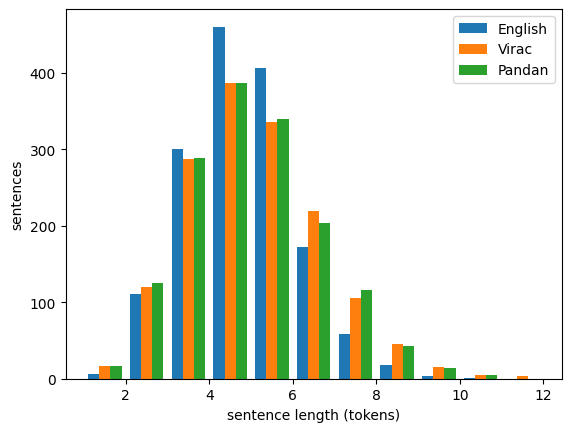

In [5]:
tok_re = lambda s: re.findall(r"[\w']+", s.lower())
rows = []
for c, name in (("en","English"), ("vi","Virac (South)"), ("pa","Pandan (North)")):
    L = [len(tok_re(s)) for s in df[c]]; T = [t for s in df[c] for t in tok_re(s)]; ct = collections.Counter(T)
    rows.append(dict(language=name, tokens=len(T), types=len(ct), TTR=round(len(ct)/len(T), 3),
                     hapax=sum(v == 1 for v in ct.values()), mean_len=round(statistics.mean(L), 2),
                     median_len=statistics.median(L), max_len=max(L)))
display(pd.DataFrame(rows))
vv = {t for s in df.vi for t in tok_re(s)}; vp = {t for s in df.pa for t in tok_re(s)}
print(f"Virac-Pandan vocabulary: {len(vv & vp)} shared types, Jaccard {len(vv & vp)/len(vv | vp):.3f}")
print(f"Identical Virac/Pandan pairs: {df.vi_equals_pa.sum()} ({df.vi_equals_pa.mean():.1%})")
import matplotlib.pyplot as plt
plt.hist([[len(tok_re(s)) for s in df[c]] for c in ("en","vi","pa")], bins=range(1,13), label=["English","Virac","Pandan"])
plt.xlabel("sentence length (tokens)"); plt.ylabel("sentences"); plt.legend(); plt.show()


## 2. LoRA fine-tuning (Tasks 2.1–2.4)

In [6]:
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainer,
                          Seq2SeqTrainingArguments, EarlyStoppingCallback, set_seed)
from peft import LoraConfig, TaskType, get_peft_model
from datasets import Dataset
set_seed(SEED)
tok = AutoTokenizer.from_pretrained(BASE_MODEL)

def build(split):
    feats = []
    for _, r in df[df.split == split].iterrows():
        for s, t in DIRECTIONS:
            tok.src_lang, tok.tgt_lang = NLLB[s], NLLB[t]
            e = tok(prep_src(r[COL[s]], t), text_target=r[COL[t]], max_length=MAX_LEN, truncation=True)
            feats.append(dict(input_ids=e["input_ids"], attention_mask=e["attention_mask"], labels=e["labels"]))
    random.Random(SEED).shuffle(feats)
    return Dataset.from_list(feats)
train_ds, val_ds = build("train"), build("validation")
print(len(train_ds), "train /", len(val_ds), "validation examples")

model = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL)
model = get_peft_model(model, LoraConfig(task_type=TaskType.SEQ_2_SEQ_LM, r=LORA_R, lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT, target_modules=["q_proj", "v_proj"], bias="none"))
model.print_trainable_parameters()

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (5 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

trainable params: 2,359,296 || all params: 617,433,088 || trainable%: 0.3821


In [7]:
import math
steps_per_epoch = math.ceil(len(train_ds) / BATCH)
WARMUP_STEPS = int(0.1 * EPOCHS * steps_per_epoch)

args = Seq2SeqTrainingArguments(
    output_dir=f"{OUT}/ckpt", num_train_epochs=EPOCHS, learning_rate=LR, lr_scheduler_type="linear",
    warmup_steps=WARMUP_STEPS, optim="adamw_torch", per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=2, load_best_model_at_end=True,
    metric_for_best_model="eval_loss", greater_is_better=False, logging_strategy="epoch",
    fp16=torch.cuda.is_available(), report_to="none", seed=SEED)
trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
    data_collator=DataCollatorForSeq2Seq(tok, model=model, label_pad_token_id=-100),
    callbacks=[EarlyStoppingCallback(5)])
trainer.train()
model.save_pretrained(f"{OUT}/adapter"); tok.save_pretrained(f"{OUT}/adapter")
print("adapter MB:", sum(os.path.getsize(f"{OUT}/adapter/{f}") for f in os.listdir(f"{OUT}/adapter")
      if f.endswith(".safetensors")) / 1e6)

Epoch,Training Loss,Validation Loss
1,3.020697,1.899070
2,1.737729,1.531301
3,1.463700,1.399544
4,1.317311,1.313880
5,1.215958,1.279966
6,1.144231,1.249931
7,1.081664,1.241289
8,1.030645,1.216271
9,0.985562,1.211742
10,0.951244,1.207481


adapter MB: 9.45752


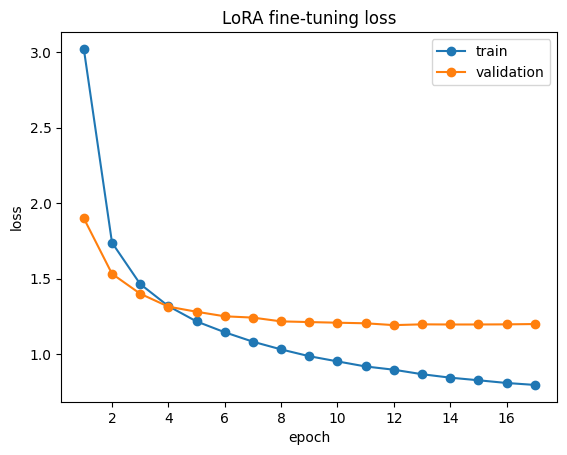

In [8]:
# train vs validation loss per epoch (overfitting check)
h = {}
for r in trainer.state.log_history:
    e = int(round(r.get("epoch", 0)))
    if "loss" in r: h.setdefault(e, {})["train"] = r["loss"]
    if "eval_loss" in r: h.setdefault(e, {})["validation"] = r["eval_loss"]
loss = pd.DataFrame(h).T.sort_index(); loss.to_csv(f"{OUT}/loss_curve.csv")
loss.plot(marker="o", xlabel="epoch", ylabel="loss", title="LoRA fine-tuning loss"); plt.savefig(f"{OUT}/loss_curve.png", dpi=150); plt.show()

## 3. Evaluation: zero-shot baseline vs fine-tuned (Tasks 4.1–4.2)
The baseline is the same NLLB weights with the adapter disabled and no dialect tags, so Bikol targets come out as Tagalog.

In [9]:
from sacrebleu.metrics import BLEU, CHRF, TER
dev = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(dev).eval()
test = df[df.split == "test"].reset_index(drop=True)

@torch.no_grad()
def translate(texts, s, t, tagged=True, beams=4, bs=32):
    tok.src_lang = NLLB[s]; out = []
    for i in range(0, len(texts), bs):
        enc = tok([prep_src(x, t, tagged) for x in texts[i:i+bs]], return_tensors="pt",
                  padding=True, truncation=True, max_length=MAX_LEN).to(dev)
        g = model.generate(**enc, forced_bos_token_id=tok.convert_tokens_to_ids(NLLB[t]), num_beams=beams, max_new_tokens=64)
        out += tok.batch_decode(g, skip_special_tokens=True)
    return out

bleu, chrf, ter = BLEU(), CHRF(word_order=2), TER()      # chrF++ = chrF with word_order=2
res, preds = [], []
for name in ("baseline", "finetuned"):
    for s, t in DIRECTIONS:
        src, ref = test[COL[s]].tolist(), test[COL[t]].tolist()
        if name == "baseline":
            with model.disable_adapter(): hyp = translate(src, s, t, tagged=False)
        else:
            hyp = translate(src, s, t, tagged=True)
        res.append(dict(model=name, direction=f"{s}->{t}", BLEU=bleu.corpus_score(hyp, [ref]).score,
                        chrFpp=chrf.corpus_score(hyp, [ref]).score, TER=ter.corpus_score(hyp, [ref]).score))
        preds += [dict(model=name, id=i, direction=f"{s}->{t}", source=a, reference=b, hypothesis=c)
                  for i, a, b, c in zip(test.id, src, ref, hyp)]
R = pd.DataFrame(res).round(2); P = pd.DataFrame(preds); P.to_csv(f"{OUT}/predictions.csv", index=False, encoding="utf-8-sig")
matrix = R.pivot(index="direction", columns="model", values=["BLEU", "chrFpp", "TER"])
matrix.loc["MACRO-AVG"] = matrix.mean()
matrix = matrix.round(2); matrix.to_csv(f"{OUT}/evaluation_matrix.csv"); display(matrix)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

BLEU             chrFpp                TER          
model                baseline finetuned baseline finetuned baseline finetuned
direction                                                                    
bcl_North->bcl_South     9.63     57.96    35.45     77.51    87.95     26.74
bcl_North->eng_Latn     17.43     38.94    38.88     56.44    86.47     50.74
bcl_South->bcl_North     9.69     61.97    34.15     80.19    90.09     23.06
bcl_South->eng_Latn     18.12     39.85    39.52     57.01    84.57     49.47
eng_Latn->bcl_North      7.35     25.31    29.47     47.32    94.31     62.51
eng_Latn->bcl_South      7.83     22.20    31.21     46.75    92.46     67.87
MACRO-AVG               11.68     41.04    34.78     60.87    89.31     46.73

In [14]:
import transformers
transformers.logging.set_verbosity_error()

In [15]:
# latency per source length (batch size 1, beam 4, fine-tuned model). Target < 300 ms.
buckets = {"1-3": (1, 3), "4-6": (4, 6), "7-9": (7, 9), "10+": (10, 999)}
lat = {k: [] for k in buckets}
translate(["warm up"], "eng_Latn", "bcl_North")
for x in test.pa.tolist()[:200]:
    n = len(x.split())
    for k, (lo, hi) in buckets.items():
        if lo <= n <= hi:
            if dev == "cuda": torch.cuda.synchronize()
            t0 = time.perf_counter(); translate([x], "bcl_North", "eng_Latn")
            if dev == "cuda": torch.cuda.synchronize()
            lat[k].append((time.perf_counter() - t0) * 1000)
L = pd.DataFrame([dict(words=k, n=len(v), mean_ms=round(statistics.mean(v)), p95_ms=round(sorted(v)[max(0, int(.95*len(v))-1)]))
                  for k, v in lat.items() if v]); L.to_csv(f"{OUT}/latency.csv", index=False); display(L)

,words,n,mean_ms,p95_ms
0,1-3,63,262,425
1,4-6,122,281,417
2,7-9,15,325,404


## 4. Linguistic error analysis (Task 4.3)
Categories are **heuristic suggestions** — review the CSV and fill `manual_category` by hand.

In [11]:
def suggest(src, ref, hyp):
    s, r, h = tok_re(src), tok_re(ref), tok_re(hyp)
    if not h: return "Untranslated (OOV)"
    if h != r and sorted(h) == sorted(r): return "Word order / Syntax"
    if h != r and len(set(h) & set(r)) / max(1, len(set(h) | set(r))) >= .6 \
       and [t for t in h if t in r] != [t for t in r if t in h]: return "Word order / Syntax"
    wrong = [t for t in h if t not in r]
    if wrong and sum(t in s for t in wrong) / len(wrong) >= .5: return "Untranslated (OOV)"
    for w in wrong:
        for m in [t for t in r if t not in h]:
            if difflib.SequenceMatcher(None, w, m).ratio() >= .6: return "Morphological / Affix"
    return "Other lexical"

F = P[(P.model == "finetuned")].copy()
F["sim"] = [difflib.SequenceMatcher(None, a.lower(), b.lower()).ratio() for a, b in zip(F.reference, F.hypothesis)]
worst = F[F.sim < 1].sort_values("sim").head(50).copy()          # 50 worst across all directions
worst["suggested_category"] = [suggest(a, b, c) for a, b, c in zip(worst.source, worst.reference, worst.hypothesis)]
worst["manual_category"] = ""; worst["notes"] = ""
worst.drop(columns="model").to_csv(f"{OUT}/error_analysis.csv", index=False, encoding="utf-8-sig")
display(worst.suggested_category.value_counts()); display(worst.head(10)[["direction", "source", "reference", "hypothesis", "suggested_category"]])

,count
suggested_category,
Other lexical,39
Untranslated (OOV),6
Morphological / Affix,5


,direction,source,reference,hypothesis,suggested_category
1580,eng_Latn->bcl_South,Vaccines do not replace cleaning.,Dai mahari ning bakuna ang paglimpya.,Dai gango sa paglilinis ning bakuna an bakuna ...,Morphological / Affix
1717,eng_Latn->bcl_North,Will there be snacks?,Ikan ning meryenda?,May snacks?,Untranslated (OOV)
1636,eng_Latn->bcl_North,Self protection.,Ingatan ang sadiri.,Self protection.,Untranslated (OOV)
1406,eng_Latn->bcl_South,Self protection.,Ingatan ang sadili.,Self protection.,Untranslated (OOV)
2328,bcl_North->eng_Latn,Mapa aki man o gurang.,Young or old.,Both grandchildren and great-grandchildren.,Other lexical
1868,bcl_South->eng_Latn,Mapa aki man o gurang.,Young or old.,Both grandchildren and great-grandchildren.,Other lexical
1597,eng_Latn->bcl_South,Goodbye for now.,Paalam na muna.,Goodbye for now.,Untranslated (OOV)
2339,bcl_North->eng_Latn,Buda iiriba ang mga barkada.,And bring friends.,Others will feel bad.,Morphological / Affix
2334,bcl_North->eng_Latn,Mag barkada kita.,We are friends.,Let us be together.,Other lexical
1874,bcl_South->eng_Latn,Mag barkada kita.,We are friends.,Let us be together.,Other lexical


## 5. Try it

In [12]:
LABELS = {"English": "eng_Latn", "Pandan (North)": "bcl_North", "Virac (South)": "bcl_South"}
import ipywidgets as w
from IPython.display import display
src_dd = w.Dropdown(options=LABELS, value="bcl_North", description="From")
tgt_dd = w.Dropdown(options=LABELS, value="eng_Latn", description="To")
box = w.Textarea(placeholder="Type text...", layout=w.Layout(width="500px", height="80px"))
out = w.HTML(); btn = w.Button(description="Translate", button_style="primary")
def go(_):
    if src_dd.value == tgt_dd.value or not box.value.strip(): return
    t0 = time.perf_counter(); y = translate([box.value.strip()], src_dd.value, tgt_dd.value)[0]
    out.value = f"<b>{y}</b> <small>({(time.perf_counter()-t0)*1000:.0f} ms)</small>"
btn.on_click(go); display(w.VBox([w.HBox([src_dd, tgt_dd]), box, btn, out]))

## 6. Save and download your results

In [13]:
import shutil
shutil.make_archive("bikol_results", "zip", OUT)
try:
    from google.colab import files; files.download("bikol_results.zip")
except ImportError: pass


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>